# Module 2: growth processes, weather data, the DSSAT file system and cultivar coefficients

This notebook follows the second day of a DSSAT training course. It runs a soybean experiment with the
CROPGRO model and looks inside the daily carbon balance, then works with weather files (quality checks,
unit conversion, what happens when the weather changes), the files a DSSAT run needs, and the three
levels of crop coefficients (species, ecotype, cultivar).

**Data.** Soybean experiment UFGA7901 (Gainesville, Florida, 1979; cultivar Bragg; irrigated and rainfed)
with its weather and soil, from [DSSAT/dssat-csm-data](https://github.com/DSSAT/dssat-csm-data) (BSD-3),
pinned to one commit. The training's own weather spreadsheet is not used; the unit-conversion exercise
starts from the published weather file instead.

**Needs.** As in module 1: the DSSAT engine, a short work folder outside OneDrive, `dssat-csm-data` next to
this repository. Results go to the work folder and to small CSV files in `docs/learn/data/module2/`.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))      # docs/notebooks
import learnlib as L
from wth import read_wth, write_wth, tav_amp

M = "module2"
EXP = "UFGA7901"
print("engine   :", L.config.engine_exe())
print("csm-data :", L.CSM_DATA, "@", L.CSM_DATA_COMMIT[:8])
print("FileX    :", L.csm_data_url(f"Soybean/{EXP}.SBX"))

engine   : C:\TEMP\dsn\dssat\dscsm048.exe
csm-data : C:\Users\benny\OneDrive\Documents\Github\dssat-csm-data @ 99c95b34
FileX    : https://github.com/DSSAT/dssat-csm-data/blob/99c95b340acb9515c2d0a8ab582f5fbbf076f345/Soybean/UFGA7901.SBX


## 1. Growth processes

### Run the experiment

UFGA7901 has two treatments: irrigated and rainfed Bragg soybean, planted on 19 June 1979.

In [2]:
FILES = [f"Soybean/{EXP}.SBX", f"Soybean/{EXP}.SBA", f"Soybean/{EXP}.SBT", f"Weather/{EXP}.WTH", "Soil/SOIL.SOL"]
run1 = L.work_dir("m2_base")
L.stage(run1, *FILES)
fx = L.filex.FileX.read(run1 / f"{EXP}.SBX")
summ, daily, res = L.run(run1, f"{EXP}.SBX")
pdate = pd.Timestamp("1979-06-19")
print(f"{len(summ)} treatments in {res.seconds:.1f} s, model {summ.MODEL.iloc[0]}")
summ[["TRNO", "TNAM", "PDAT", "ADAT", "MDAT", "HWAM", "CWAM", "LAIX", "PRCM", "IRCM", "ETCM", "NFXM"]]

2 treatments in 0.8 s, model CRGRO048


,TRNO,TNAM,PDAT,ADAT,MDAT,HWAM,CWAM,LAIX,PRCM,IRCM,ETCM,NFXM
0,1,79 IRRIG. BRAGG,1979170,1979213,1979285,3114,6314,5.537128,695,113,461,302
1,2,79 RAINFED BRAGG,1979170,1979213,1979285,3061,5994,5.282708,695,0,442,294


In [3]:
def to_date(v, year=1979):
    v = int(v)
    if v > 1_000_000:
        return pd.to_datetime(str(v), format="%Y%j")
    if v < 1000:                       # day of year only, as in this FileA
        return pd.Timestamp(year, 1, 1) + pd.Timedelta(days=v - 1)
    return L._date(v)

obsA = L._read_table(run1 / f"{EXP}.SBA")     # dates here are days of the year, handled by to_date
rows = []
for _, s in summ.iterrows():
    o = obsA[obsA.TRNO == s.TRNO].iloc[0]
    for var, sim, ob in [("Seed yield, kg/ha", s.HWAM, o.HWAM), ("Tops weight, kg/ha", s.CWAM, o.CWAM),
                         ("Pod weight, kg/ha", s.PWAM, o.PWAM), ("LAI, maximum", s.LAIX, o.LAIX),
                         ("Seed size, g", float(s.HWUM) * 1000 if pd.notna(s.HWUM) else np.nan, o.HWUM * 1000),
                         ("First flower (R1), DAP", (to_date(s.ADAT) - pdate).days, (to_date(o.ADAT) - pdate).days),
                         ("Maturity, DAP", (to_date(s.MDAT) - pdate).days, (to_date(o.MDAT) - pdate).days)]:
        rows.append({"TRNO": int(s.TRNO), "treatment": ["irrigated", "rainfed"][int(s.TRNO) - 1],
                     "variable": var, "simulated": float(sim), "observed": float(ob)})
final = pd.DataFrame(rows)
final["sim/obs"] = final.simulated / final.observed
final.round(2)

,TRNO,treatment,variable,simulated,observed,sim/obs
0,1,irrigated,"Seed yield, kg/ha",3114.00,2891.00,1.08
1,1,irrigated,"Tops weight, kg/ha",6314.00,5781.00,1.09
2,1,irrigated,"Pod weight, kg/ha",3987.00,3734.00,1.07
3,1,irrigated,"LAI, maximum",5.54,4.71,1.18
4,1,irrigated,"Seed size, g",152.17,163.80,0.93
5,1,irrigated,"First flower (R1), DAP",43.00,43.00,1.00
6,1,irrigated,"Maturity, DAP",115.00,119.00,0.97
7,2,rainfed,"Seed yield, kg/ha",3061.00,2883.00,1.06
8,2,rainfed,"Tops weight, kg/ha",5994.00,5534.00,1.08
9,2,rainfed,"Pod weight, kg/ha",3920.00,3755.00,1.04


### The daily carbon balance

CROPGRO computes gross photosynthesis every day, takes off maintenance respiration (a part proportional to
the plant's mass and a part proportional to the day's photosynthesis,
[`RESPIR.for:54`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Plant/CROPGRO/RESPIR.for#L54)), and turns what is left into new tissue, losing
growth respiration in the conversion. With the `PHOTO` method `L` of this experiment the gross photosynthesis
comes from an hourly leaf-level calculation in the soil-plant-atmosphere module
([`CROPGRO.for:748-758`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Plant/CROPGRO/CROPGRO.for#L748)); with `C` it is the daily canopy equation of
[`PHOTO.for:225`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Plant/CROPGRO/PHOTO.for#L225), which multiplies a light-limited rate by 0-1 factors for
soil fertility (`SLPF`), temperature, leaf N, water and CO2.

The daily output file `PlantC` reports these terms in g CH2O per m2 per day.

In [4]:
pc = daily["plantc"]
carbon = pc[["TRNO", "date", "DAP", "PHAD", "MRAD", "GRAD", "CGRD", "CMAD"]].copy()
carbon = carbon[carbon.DAP >= 0]
tot = carbon.groupby("TRNO")[["PHAD", "MRAD", "GRAD", "CGRD"]].sum()
tot["respired share"] = (tot.MRAD + tot.GRAD) / tot.PHAD
tot.round(2)

,PHAD,MRAD,GRAD,CGRD,respired share
TRNO,,,,,
1,2445.16,541.0,457.58,1258.55,0.41
2,2379.05,524.5,447.97,1225.09,0.41


Text(0.5, 1.0, 'Irrigated Bragg, 1979')

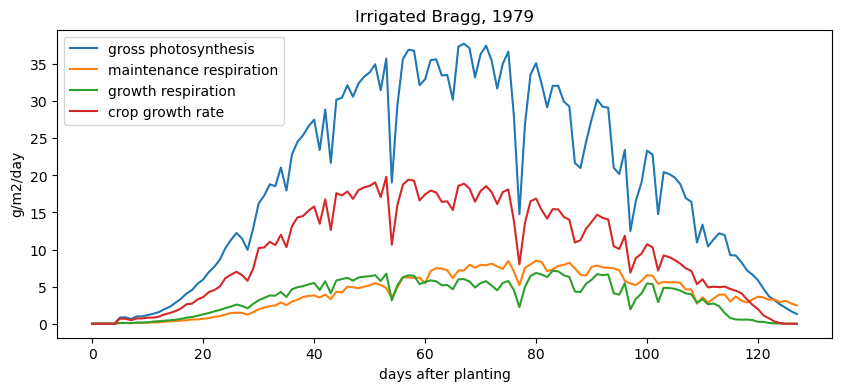

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
c1 = carbon[carbon.TRNO == 1]
for v, lab in [("PHAD", "gross photosynthesis"), ("MRAD", "maintenance respiration"), ("GRAD", "growth respiration"), ("CGRD", "crop growth rate")]:
    ax.plot(c1.DAP, c1[v], label=lab)
ax.set_xlabel("days after planting"); ax.set_ylabel("g/m2/day"); ax.legend(); ax.set_title("Irrigated Bragg, 1979")

### Where the new mass goes: partitioning

Each day the new dry matter is shared between leaves, stems, roots and (after flowering) pods and seeds,
in proportions that change with the growth stage. The FileT holds field samples of the same organs.

In [6]:
pg = daily["plantgro"]
gsim = pg[["TRNO", "date", "DAP", "GSTD", "LAID", "LWAD", "SWAD", "RWAD", "PWAD", "GWAD", "CWAD", "WSPD", "WSGD", "NSTD"]].copy()
gsim = gsim[gsim.DAP >= 0]
gsim["SHAD"] = gsim.PWAD - gsim.GWAD
obsT = L.read_filet(run1 / f"{EXP}.SBT")
keep = [c for c in ["LAID", "LWAD", "SWAD", "PWAD", "GWAD", "CWAD"] if c in obsT]
gobs = obsT[["TRNO", "date"] + keep].copy()
gobs["DAP"] = (gobs.date - pdate).dt.days

stats = []
for t in sorted(gobs.TRNO.unique()):
    s = gsim[gsim.TRNO == t].set_index("date")
    for var in keep:
        o = gobs[gobs.TRNO == t][["date", var]].dropna()
        o = o[o.date.isin(s.index)]
        stats.append({"TRNO": t, "variable": var, "n": len(o), "rmse": L.rmse(o[var], s.loc[o.date, var]),
                      "d": L.willmott_d(o[var], s.loc[o.date, var])})
stats = pd.DataFrame(stats)
stats = stats[stats.n > 0]           # the FileT also holds a treatment the FileX has commented out
stats.pivot(index="variable", columns="TRNO", values=["rmse", "d"]).round(2)

rmse             d      
TRNO           1       2     1     2
variable                            
CWAD      567.31  874.36  0.99  0.97
GWAD      196.34  367.94  0.99  0.97
LAID        0.57    0.69  0.97  0.96
LWAD      199.86  266.20  0.98  0.95
PWAD      284.00  487.53  0.99  0.97
SWAD      381.54  472.34  0.97  0.95

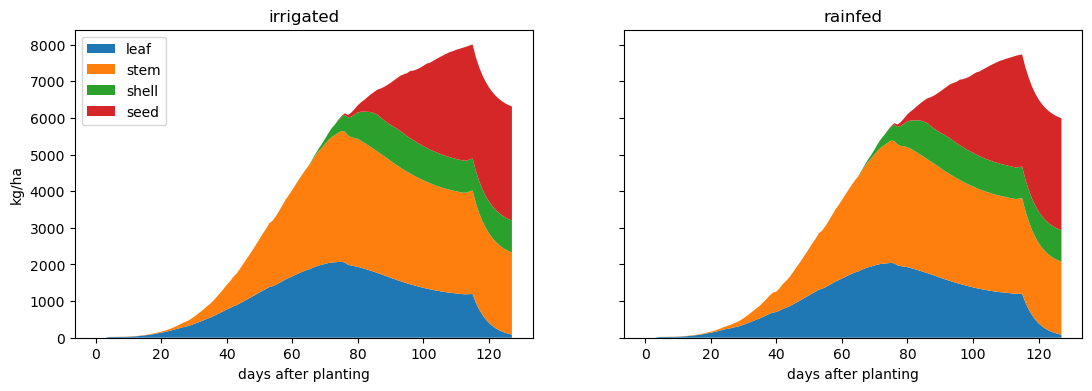

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, t in zip(axs, [1, 2]):
    g = gsim[gsim.TRNO == t]
    ax.stackplot(g.DAP, g.LWAD, g.SWAD, g.SHAD, g.GWAD, labels=["leaf", "stem", "shell", "seed"])
    ax.set_title(["irrigated", "rainfed"][t - 1]); ax.set_xlabel("days after planting")
axs[0].set_ylabel("kg/ha"); axs[0].legend(loc="upper left")

### Light interception

Gross photosynthesis depends first on how much light the canopy intercepts. The engine reports the
intercepted share of PAR (`LI%D`) and the leaf area index; Beer's law, `LI = 1 - exp(-k LAI)`, gives an
extinction coefficient `k` that summarises the canopy.

In [8]:
et = daily["etphot"][["TRNO", "date", "LI%D"]]
light = gsim[["TRNO", "date", "DAP", "LAID"]].merge(et, on=["TRNO", "date"])
light = light.rename(columns={"LI%D": "LI"})
ok = (light.LAID > 0.05) & (light.LI > 0) & (light.LI < 99.5)
x, y = light.LAID[ok].values, -np.log(1 - light.LI[ok].values / 100)
k = float(np.sum(x * y) / np.sum(x * x))       # least squares through the origin
print(f"fitted extinction coefficient k = {k:.3f} from {ok.sum()} days")
light["LI_beer"] = 100 * (1 - np.exp(-k * light.LAID))

fitted extinction coefficient k = 0.720 from 238 days


### Water stress

The rainfed treatment had the same weather but no irrigation. Two 0-1 factors in `PlantGro` show when water
was short: `WSPD` (photosynthesis) and `WSGD` (expansion, partitioning and development). In CROPGRO's
`PlantGro` these are written as `1 - factor` ([`Opgrow.for:277-278`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Plant/CROPGRO/Opgrow.for#L277)): 0 means
no stress, 1 means growth stopped.

In [9]:
wb = daily["soilwat"][["TRNO", "date", "PREC", "IRRC", "SWXD"]]
wd = daily["weather"][["TRNO", "date", "PRED", "DAYLD", "TMXD", "TMND", "SRAD"]]
stress = gsim[["TRNO", "date", "DAP", "WSPD", "WSGD"]].merge(wd, on=["TRNO", "date"]).merge(wb, on=["TRNO", "date"])
stress.groupby("TRNO")[["WSPD", "WSGD"]].agg(["mean", "max"]).round(2)

WSPD        WSGD      
      mean   max  mean   max
TRNO                        
1     0.00  0.00  0.00  0.17
2     0.01  0.38  0.03  0.58

### Two ways to compute photosynthesis

The same experiment with the daily canopy method (`PHOTO` = `C`) instead of the hourly leaf method:

In [10]:
d = L.work_dir("m2_photoC")
L.stage(d, f"Weather/{EXP}.WTH", "Soil/SOIL.SOL")
u = pd.DataFrame({"cell": ["irrigated", "rainfed"], "name": ["irrigated, PHOTO C", "rainfed, PHOTO C"], "wsta": EXP,
                  "soil_id": "IBSB910015", "pdate": pdate, "trno_template": [1, 2]})
name, u = L.write_built(d, fx, u, "UFGA7911", ".SBX", title="Canopy photosynthesis", switches={"PHOTO": "C"})
sC, _, _ = L.run(d, name, outputs="summary")
photo = pd.DataFrame({"treatment": ["irrigated", "rainfed"], "HWAM_L": summ.HWAM.astype(float).values,
                      "HWAM_C": sC.HWAM.astype(float).values, "CWAM_L": summ.CWAM.astype(float).values,
                      "CWAM_C": sC.CWAM.astype(float).values})
photo["obs_HWAM"] = obsA.HWAM.values
photo

,treatment,HWAM_L,HWAM_C,CWAM_L,CWAM_C,obs_HWAM
0,irrigated,3114.0,2899.0,6314.0,6264.0,2891.0
1,rainfed,3061.0,2854.0,5994.0,5965.0,2883.0


In [11]:
tmeta = pd.DataFrame({"TRNO": [1, 2], "treatment": ["irrigated", "rainfed"],
                      "TNAME": list(fx.treatments().TNAME.str.strip())})
L.export(tmeta, M, "treatments"); L.export(final, M, "final")
L.export(gsim, M, "growth_sim"); L.export(gobs, M, "growth_obs"); L.export(stats, M, "stats")
L.export(carbon, M, "carbon"); L.export(tot.reset_index(), M, "carbon_totals")
L.export(light[["TRNO", "DAP", "LAID", "LI", "LI_beer"]], M, "light")
L.export(pd.DataFrame([{"k": k, "days": int(ok.sum())}]), M, "light_fit", 4)
L.export(stress, M, "stress"); L.export(photo, M, "photo_method")

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module2/photo_method.csv')

### The effect of CO2 on growth

Photosynthesis responds to the CO2 concentration of the air, and differently in C3 crops (soybean) and C4 crops
(maize). The environmental modification column `ECO2` of an experiment file can replace the CO2 of every day
with a fixed value (`R` and the value, in ppm). The irrigated soybean of UFGA7901 and the irrigated, high-N maize
of UFGA8201 are run at six concentrations, one treatment per concentration.

In [12]:
CO2S = [280, 330, 380, 450, 550, 700]

def co2_runs(src_rel, trno, exp_new, ext, start_doy, year, files, crop):
    t = (L.CSM_DATA / src_rel).read_text(encoding="latin-1").replace(chr(26), "")
    sec = t[t.index("*TREATMENTS"):]
    sec = sec[:sec.index("*", 1)].rstrip().splitlines()
    hdr, tpl = sec[1], next(ln for ln in sec[2:] if ln[:2].strip() == str(trno))
    me_col = hdr.index(" ME") + 3
    new = [sec[0], hdr]
    for i, c in enumerate(CO2S, 1):
        row = f"{i:>2}" + tpl[2:9] + f"{('CO2 ' + str(c) + ' PPM'):<25}" + tpl[34:]
        row = row[:me_col - 3] + f"{i:>3}" + row[me_col:]
        new.append(row)
    t = L.replace_section(t, "TREATMENTS", "\n".join(new))
    env = ["*ENVIRONMENT MODIFICATIONS", "@E ODATE EDAY  ERAD  EMAX  EMIN  ERAIN ECO2  EDEW  EWIND ENVNAME"]
    env += [f"{i:>2} {year:02d}{start_doy:03d} A   0 A   0 A   0 A   0 A 0.0 R{c:>4} A   0 A   0" for i, c in enumerate(CO2S, 1)]
    if "*ENVIRONMENT MODIFICATIONS" in t:
        t = L.replace_section(t, "ENVIRONMENT MODIFICATIONS", "\n".join(env))
    else:
        t = t.replace("*SIMULATION CONTROLS", "\n".join(env) + "\n\n*SIMULATION CONTROLS", 1)
    d = L.work_dir("m2_co2_" + crop)
    L.stage(d, *files)
    (d / (exp_new + ext)).write_text(t, encoding="latin-1")
    s, _, _ = L.run(d, exp_new + ext, outputs="summary")
    return pd.DataFrame({"crop": crop, "CO2": CO2S, "HWAM": pd.to_numeric(s.HWAM, errors="coerce").values,
                         "CWAM": pd.to_numeric(s.CWAM, errors="coerce").values, "ETCM": pd.to_numeric(s.ETCM, errors="coerce").values})

co2 = pd.concat([co2_runs(f"Soybean/{EXP}.SBX", 1, "UFGA7915", ".SBX", 170, 79, [f"Weather/{EXP}.WTH", "Soil/SOIL.SOL"], "soybean (C3)"),
                 co2_runs("Maize/UFGA8201.MZX", 4, "UFGA8216", ".MZX", 56, 82, ["Weather/UFGA8201.WTH", "Soil/SOIL.SOL"], "maize (C4)")])
base380 = co2[co2.CO2 == 380].set_index("crop").HWAM
co2["relative_yield"] = co2.HWAM / co2.crop.map(base380)
L.export(co2, M, "co2_response", 4)
co2.pivot(index="CO2", columns="crop", values="relative_yield").round(3)

crop,maize (C4),soybean (C3)
CO2,,
280,0.897,0.820
330,0.987,0.921
380,1.000,1.000
450,1.016,1.074
550,1.031,1.157
700,1.039,1.238


## 2. Weather data

A DSSAT weather file holds one station header (code, latitude, longitude, elevation, `TAV` the mean annual
temperature and `AMP` the amplitude of monthly mean temperatures) and one row per day with at least solar
radiation (MJ/m2/day), maximum and minimum temperature (°C) and rain (mm). The shell's WeatherMan tool
imports, checks and converts such data; here pandas and `src/wth.py` do the same.

### Quality checks

In [13]:
station, w = read_wth(run1 / f"{EXP}.WTH")
w = w.rename(columns=str.upper)
print(station)
checks = pd.DataFrame([
    {"check": "days in file", "count": len(w)},
    {"check": "missing values (any of SRAD, TMAX, TMIN, RAIN)", "count": int(w[["SRAD", "TMAX", "TMIN", "RAIN"]].isna().any(axis=1).sum())},
    {"check": "TMAX below TMIN", "count": int((w.TMAX < w.TMIN).sum())},
    {"check": "negative rain", "count": int((w.RAIN < 0).sum())},
    {"check": "SRAD below 0 or above 35 MJ/m2/day", "count": int(((w.SRAD < 0) | (w.SRAD > 35)).sum())},
    {"check": "TMAX above 45 or TMIN below -20 °C", "count": int(((w.TMAX > 45) | (w.TMIN < -20)).sum())},
    {"check": "day-to-day TMAX change above 15 °C", "count": int((w.TMAX.diff().abs() > 15).sum())},
    {"check": "gaps in the dates", "count": int((pd.Series(w.index).diff().dt.days.dropna() != 1).sum())},
])
tav, amp = tav_amp(w.TMAX, w.TMIN, w.index)
tavamp = pd.DataFrame([{"what": "TAV, °C", "header": station.get("TAV"), "recomputed": round(tav, 2)},
                       {"what": "AMP, °C", "header": station.get("AMP"), "recomputed": round(amp, 2)}])
display(checks); tavamp

{'INSI': 'UFGA', 'LAT': 29.63, 'LONG': -82.37, 'ELEV': 10.0, 'TAV': 20.9, 'AMP': 13.0, 'REFHT': 2.0, 'WNDHT': 3.0}


,check,count
0,days in file,365
1,"missing values (any of SRAD, TMAX, TMIN, RAIN)",0
2,TMAX below TMIN,0
3,negative rain,0
4,SRAD below 0 or above 35 MJ/m2/day,0
5,TMAX above 45 or TMIN below -20 °C,0
6,day-to-day TMAX change above 15 °C,1
7,gaps in the dates,0


,what,header,recomputed
0,"TAV, °C",20.9,20.99
1,"AMP, °C",13.0,16.09


,month,TMAX,TMIN,SRAD,RAIN,raindays
0,1,18.9,5.5,10.2,220.6,9
1,2,20.3,5.6,11.9,84.9,6
2,3,25.1,9.2,18.2,29.7,4
3,4,28.2,15.1,19.1,207.8,7
4,5,30.0,17.0,21.3,85.4,10
5,6,32.6,20.1,20.4,115.7,10
6,7,34.0,22.6,21.1,111.2,18
7,8,33.0,21.8,19.3,187.7,14
8,9,31.1,22.2,14.2,310.8,18
9,10,29.3,14.9,16.7,2.8,3


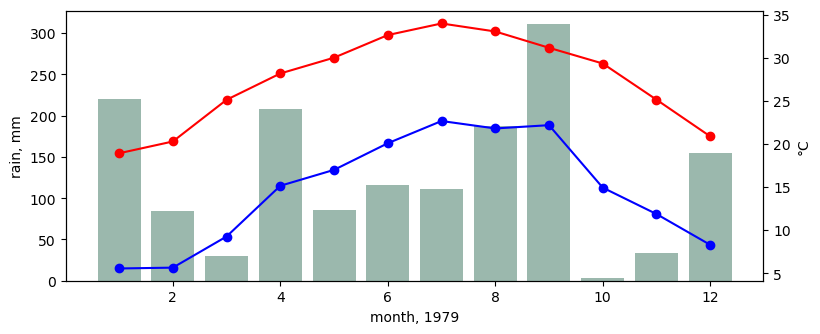

In [14]:
monthly = w.assign(month=w.index.month).groupby("month").agg(TMAX=("TMAX", "mean"), TMIN=("TMIN", "mean"),
                                                            SRAD=("SRAD", "mean"), RAIN=("RAIN", "sum"),
                                                            raindays=("RAIN", lambda r: int((r > 0).sum()))).reset_index()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(monthly.month, monthly.RAIN, color="#9bb8ad", label="rain, mm"); ax2 = ax.twinx()
ax2.plot(monthly.month, monthly.TMAX, "r-o", label="Tmax"); ax2.plot(monthly.month, monthly.TMIN, "b-o", label="Tmin")
ax.set_xlabel("month, 1979"); ax.set_ylabel("rain, mm"); ax2.set_ylabel("°C")
monthly.round(1)

### The WeatherMan exercise: weather from Griffin, Georgia

The course hands out daily weather of an experiment station at Griffin, Georgia, as a spreadsheet
(`course-data/GRGR-Raw.xls`): the date as `YYDDD`, rain in inches, maximum and minimum temperature in °F and
solar radiation in cal/cm² (langleys). The exercise gives the station as latitude 33°16' N, longitude
84°17' W, elevation 299 m. WeatherMan converts the units, checks the data and writes one DSSAT weather file
per year, `GRGR9201.WTH` to `GRGR9901.WTH`; here pandas and `wth.write_wth` do the same.

In [15]:
raw = pd.read_excel(L.COURSE / "GRGR-Raw.xls", header=None, names=["YYDDD", "rain_in", "tmax_F", "tmin_F", "srad_ly"])
raw["date"] = [L._date(v) for v in raw.YYDDD]
print(f"{len(raw)} days, {raw.date.min():%d %b %Y} to {raw.date.max():%d %b %Y}")
print(raw.head(5).to_string(index=False))
gr = pd.DataFrame({"SRAD": raw.srad_ly * 0.04184, "TMAX": (raw.tmax_F - 32) * 5 / 9,
                   "TMIN": (raw.tmin_F - 32) * 5 / 9, "RAIN": raw.rain_in * 25.4}).set_index(pd.DatetimeIndex(raw.date))
full = pd.date_range(gr.index.min(), gr.index.max())
gchecks = pd.DataFrame([
    {"check": "days in the spreadsheet", "count": len(gr)},
    {"check": "duplicate dates", "count": int(gr.index.duplicated().sum())},
    {"check": "days missing between first and last date", "count": int(len(full.difference(gr.index)))},
    {"check": "missing values", "count": int(gr.isna().any(axis=1).sum())},
    {"check": "TMAX below TMIN", "count": int((gr.TMAX < gr.TMIN).sum())},
    {"check": "negative rain", "count": int((gr.RAIN < 0).sum())},
    {"check": "SRAD below 0 or above 35 MJ/m2/day", "count": int(((gr.SRAD < 0) | (gr.SRAD > 35)).sum())},
])
gchecks

2696 days, 01 Jan 1992 to 19 May 1999
 YYDDD  rain_in  tmax_F  tmin_F  srad_ly       date
 92001     0.00    50.5    35.1   138.62 1992-01-01
 92002     1.37    49.3    40.6    59.75 1992-01-02
 92003     0.35    53.8    42.1   126.67 1992-01-03
 92004     0.00    61.9    42.6   255.74 1992-01-04
 92005     0.00    53.4    42.1   162.52 1992-01-05


,check,count
0,days in the spreadsheet,2696
1,duplicate dates,0
2,days missing between first and last date,0
3,missing values,0
4,TMAX below TMIN,0
5,negative rain,0
6,SRAD below 0 or above 35 MJ/m2/day,0


In [16]:
LAT, LON, ELEV = 33 + 16 / 60, -(84 + 17 / 60), 299
gr = gr[~gr.index.duplicated()].reindex(full)
filled = int(gr.isna().any(axis=1).sum())
gr[["SRAD", "TMAX", "TMIN"]] = gr[["SRAD", "TMAX", "TMIN"]].interpolate(limit_direction="both")
gr["RAIN"] = gr.RAIN.fillna(0.0)
tav_g, amp_g = tav_amp(gr.TMAX, gr.TMIN, gr.index)
dgr = L.work_dir("m2_grgr")
written = []
for year, part in gr.groupby(gr.index.year):
    f = dgr / f"GRGR{year % 100:02d}01.WTH"
    write_wth(f, part, insi="GRGR", lat=LAT, lon=LON, elev=ELEV, tav=tav_g, amp=amp_g,
              title="Experiment, Georgia, USA (course data, converted)", seven_digit=False)
    written.append({"file": f.name, "days": len(part), "first": part.index.min(), "last": part.index.max()})
written = pd.DataFrame(written)
print(f"days filled by interpolation (temperature, radiation) or as no rain: {filled}; TAV {tav_g:.1f}, AMP {amp_g:.1f}")
print("\n".join((dgr / "GRGR9201.WTH").read_text().splitlines()[:7]))
written

days filled by interpolation (temperature, radiation) or as no rain: 0; TAV 16.2, AMP 19.3
*WEATHER : Experiment, Georgia, USA (course data, converted)

@ INSI      LAT     LONG  ELEV   TAV   AMP REFHT WNDHT
  GRGR   33.267  -84.283   299  16.2  19.3   -99   -99
@DATE  SRAD  TMAX  TMIN  RAIN
92001   5.8  10.3   1.7   0.0
92002   2.5   9.6   4.8  34.8


,file,days,first,last
0,GRGR9201.WTH,366,1992-01-01,1992-12-31
1,GRGR9301.WTH,365,1993-01-01,1993-12-31
2,GRGR9401.WTH,365,1994-01-01,1994-12-31
3,GRGR9501.WTH,365,1995-01-01,1995-12-31
4,GRGR9601.WTH,366,1996-01-01,1996-12-31
5,GRGR9701.WTH,365,1997-01-01,1997-12-31
6,GRGR9801.WTH,365,1998-01-01,1998-12-31
7,GRGR9901.WTH,139,1999-01-01,1999-05-19


**Self test 1 of the exercise**: run the first treatment of the maize experiment UFGA8201 with the new
weather. The Griffin record covers 1992-1999, not 1982, so the experiment is planted on 26 February of
each year from 1992 to 1998 (all its dates move with planting), next to Gainesville 1982.

In [17]:
fxm = L.filex.FileX.read(L.CSM_DATA / "Maize/UFGA8201.MZX")
L.stage(dgr, "Weather/UFGA8201.WTH", "Soil/SOIL.SOL")
rows = [{"cell": "UFGA 1982", "name": "Gainesville 1982", "wsta": "UFGA", "pdate": pd.Timestamp("1982-02-26")}]
rows += [{"cell": f"GRGR {y}", "name": f"Griffin {y}", "wsta": "GRGR", "pdate": pd.Timestamp(f"{y}-02-26")} for y in range(1992, 1999)]
u = pd.DataFrame(rows).assign(soil_id="IBMZ910014", trno_template=1)
name, u = L.write_built(dgr, fxm, u, "GRGR9201", ".MZX", title="UFGA8201 treatment 1 with Griffin weather")
sg, _, _ = L.run(dgr, name, outputs="summary")
grgr_runs = sg.merge(u[["TRNO", "cell"]], on="TRNO")[["cell", "PDAT", "ADAT", "MDAT", "HWAM", "CWAM", "PRCM", "ETCM", "TMAXA", "TMINA", "SRADA"]]
for c in grgr_runs.columns[1:]:
    grgr_runs[c] = pd.to_numeric(grgr_runs[c], errors="coerce")
grgr_runs["season_days"] = [(L._date(m) - L._date(p)).days for p, m in zip(grgr_runs.PDAT, grgr_runs.MDAT)]
grgr_runs

,cell,PDAT,ADAT,MDAT,HWAM,CWAM,PRCM,ETCM,TMAXA,TMINA,SRADA,season_days
0,UFGA 1982,1982057,1982133,1982185,2293,6556,661,290,29.332031,16.024216,18.540625,128
1,GRGR 1992,1992057,1992167,1992222,6924,11795,471,346,25.061211,13.146670,19.460003,165
2,GRGR 1993,1993057,1993167,1993218,1464,4183,426,239,25.719259,13.336024,20.972052,161
3,GRGR 1994,1994057,1994159,1994216,6703,12884,1069,422,25.617609,13.870437,19.800003,159
4,GRGR 1995,1995057,1995155,1995211,4218,9585,289,265,26.640911,13.874025,20.588306,154
5,GRGR 1996,1996057,1996167,1996220,3687,9596,497,291,25.870558,12.854602,20.098162,163
6,GRGR 1997,1997057,1997162,1997218,6446,13021,632,382,25.588198,12.955901,19.718630,161
7,GRGR 1998,1998057,1998158,1998209,3418,6425,562,267,26.531584,13.650656,20.226971,152


In [18]:
gm = gr.assign(year=gr.index.year, month=gr.index.month).groupby(["year", "month"]).agg(
    TMAX=("TMAX", "mean"), TMIN=("TMIN", "mean"), SRAD=("SRAD", "mean"), RAIN=("RAIN", "sum")).reset_index()
L.export(raw.drop(columns=["date"]).head(400), M, "grgr_raw")
L.export(gr.rename_axis("date").reset_index(), M, "grgr_daily", 2)
L.export(gm, M, "grgr_monthly", 2); L.export(gchecks, M, "grgr_checks"); L.export(written, M, "grgr_files")
L.export(pd.DataFrame([{"lat": LAT, "lon": LON, "elev": ELEV, "TAV": tav_g, "AMP": amp_g, "filled": filled}]), M, "grgr_station", 3)
L.export(grgr_runs, M, "grgr_maize")

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module2/grgr_maize.csv')

### Converting back and forth: an optional column matters

Station data often come in other units: °F, inches of rain, radiation in langleys (cal/cm2/day). To show the
conversion WeatherMan does on import, the published file is turned into such a table, converted back with
the standard factors (1 inch = 25.4 mm, 1 langley = 0.04184 MJ/m2) and written as a new DSSAT file with
`wth.write_wth`, which also recomputes `TAV` and `AMP`. This file also has a `PAR` column
(photosynthetically active radiation, mol/m2/day); the conversion is done twice, once keeping it and once
without it, and the soybean experiment is run on each new file.

In [19]:
raw = pd.DataFrame({"date": w.index, "tmax_F": w.TMAX * 9 / 5 + 32, "tmin_F": w.TMIN * 9 / 5 + 32,
                    "rain_in": w.RAIN / 25.4, "srad_ly": w.SRAD / 0.04184}).round(2)
print(raw.head())      # what a station logger might deliver

conv = pd.DataFrame({"SRAD": raw.srad_ly * 0.04184, "TMAX": (raw.tmax_F - 32) * 5 / 9,
                     "TMIN": (raw.tmin_F - 32) * 5 / 9, "RAIN": raw.rain_in * 25.4}).set_index(pd.DatetimeIndex(raw.date))
d = L.work_dir("m2_wth_import")
L.stage(d, f"Soybean/{EXP}.SBX", "Soil/SOIL.SOL")
write_wth(d / f"{EXP}.WTH", conv, insi="UFGA", lat=station["LAT"], lon=station["LONG"], elev=station.get("ELEV"),
          title="UFGA7901 converted from imperial units", seven_digit=False)
st2, w2 = read_wth(d / f"{EXP}.WTH"); w2 = w2.rename(columns=str.upper)
sNoPar, _, _ = L.run(d, f"{EXP}.SBX", outputs="summary")
d2 = L.work_dir("m2_wth_import_par")
L.stage(d2, f"Soybean/{EXP}.SBX", "Soil/SOIL.SOL")
write_wth(d2 / f"{EXP}.WTH", conv.assign(PAR=w.PAR.values), insi="UFGA", lat=station["LAT"], lon=station["LONG"],
          elev=station.get("ELEV"), title="UFGA7901 converted from imperial units, PAR kept", seven_digit=False)
sPar, _, _ = L.run(d2, f"{EXP}.SBX", outputs="summary")
roundtrip = pd.DataFrame([{"variable": f"{c}, largest change", "value": float((w2[c] - w[c]).abs().max())} for c in ["SRAD", "TMAX", "TMIN", "RAIN"]]
                         + [{"variable": f"seed yield {t}, original file", "value": float(a)} for t, a in zip(["irrigated", "rainfed"], summ.HWAM.astype(float))]
                         + [{"variable": f"seed yield {t}, converted, PAR kept", "value": float(a)} for t, a in zip(["irrigated", "rainfed"], sPar.HWAM.astype(float))]
                         + [{"variable": f"seed yield {t}, converted, no PAR", "value": float(a)} for t, a in zip(["irrigated", "rainfed"], sNoPar.HWAM.astype(float))])
print("TAV/AMP of the new file:", st2.get("TAV"), st2.get("AMP"))
roundtrip

C:\TEMP\ipykernel_46484\1818243184.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "rain_in": w.RAIN / 25.4, "srad_ly": w.SRAD / 0.04184}).round(2)


                 date  tmax_F  tmin_F  rain_in  srad_ly
date                                                   
1979-01-01 1979-01-01   80.96   57.92     0.00   239.01
1979-01-02 1979-01-02   78.98   46.04     1.35    62.14
1979-01-03 1979-01-03   46.04   23.00     0.00   296.37
1979-01-04 1979-01-04   50.00   26.96     0.00   246.18
1979-01-05 1979-01-05   69.98   39.02     0.00   270.08


TAV/AMP of the new file: 21.0 16.1


,variable,value
0,"SRAD, largest change",0.0
1,"TMAX, largest change",0.0
2,"TMIN, largest change",0.0
3,"RAIN, largest change",0.1
4,"seed yield irrigated, original file",3114.0
5,"seed yield rainfed, original file",3061.0
6,"seed yield irrigated, converted, PAR kept",3114.0
7,"seed yield rainfed, converted, PAR kept",3063.0
8,"seed yield irrigated, converted, no PAR",3187.0
9,"seed yield rainfed, converted, no PAR",3135.0


### What if the weather were different?

Each scenario changes the weather file and reruns both treatments: radiation (SRAD and PAR) scaled by 0.8
to 1.2, all temperatures raised by 2 or 4 °C, and rain halved or raised by half. This is what the
*environmental modification* section of a FileX does inside the engine; editing the file keeps the change
visible.

In [20]:
SCEN = {"baseline": {}, "SRAD x 0.8": {"SRAD": ("mul", 0.8)}, "SRAD x 0.9": {"SRAD": ("mul", 0.9)},
        "SRAD x 1.1": {"SRAD": ("mul", 1.1)}, "SRAD x 1.2": {"SRAD": ("mul", 1.2)},
        "temperature +2 °C": {"TMAX": ("add", 2), "TMIN": ("add", 2)},
        "temperature +4 °C": {"TMAX": ("add", 4), "TMIN": ("add", 4)},
        "rain x 0.5": {"RAIN": ("mul", 0.5)}, "rain x 1.5": {"RAIN": ("mul", 1.5)}}
sens_w = []
for sname, change in SCEN.items():
    d = L.work_dir("m2_w_" + "".join(ch for ch in sname if ch.isalnum()))
    L.stage(d, f"Soybean/{EXP}.SBX", "Soil/SOIL.SOL")
    ww = w[["SRAD", "TMAX", "TMIN", "RAIN", "PAR"]].copy()
    for col, (op, v) in change.items():
        ww[col] = ww[col] * v if op == "mul" else ww[col] + v
        if col == "SRAD":
            ww["PAR"] = ww["PAR"] * v          # PAR is part of the radiation
    write_wth(d / f"{EXP}.WTH", ww, insi="UFGA", lat=station["LAT"], lon=station["LONG"], elev=station.get("ELEV"),
              title=sname.replace("°", "deg"), seven_digit=False)
    s, _, _ = L.run(d, f"{EXP}.SBX", outputs="summary")
    for _, r in s.iterrows():
        sens_w.append({"scenario": sname, "treatment": ["irrigated", "rainfed"][int(r.TRNO) - 1],
                       "HWAM": float(r.HWAM), "CWAM": float(r.CWAM),
                       "R1_dap": (to_date(r.ADAT) - pdate).days, "maturity_dap": (to_date(r.MDAT) - pdate).days,
                       "IRCM": float(r.IRCM), "ETCM": float(r.ETCM)})
sens_w = pd.DataFrame(sens_w)
base = sens_w[sens_w.scenario == "baseline"].set_index("treatment").HWAM
sens_w["change"] = sens_w.HWAM / sens_w.treatment.map(base) - 1
sens_w.pivot(index="scenario", columns="treatment", values="HWAM")

treatment,irrigated,rainfed
scenario,,
SRAD x 0.8,2627.0,2628.0
SRAD x 0.9,2898.0,2874.0
SRAD x 1.1,3274.0,3173.0
SRAD x 1.2,3421.0,3254.0
baseline,3114.0,3063.0
rain x 0.5,2912.0,2203.0
rain x 1.5,3105.0,3098.0
temperature +2 °C,2848.0,2781.0
temperature +4 °C,2589.0,2431.0


In [21]:
season = w.loc["1979-06-19":"1979-11-15"].reset_index().rename(columns={"index": "date"})
season = season.rename(columns={season.columns[0]: "date"})
L.export(season[["date", "SRAD", "TMAX", "TMIN", "RAIN"]], M, "weather_season")
L.export(monthly, M, "weather_monthly"); L.export(checks, M, "weather_checks"); L.export(tavamp, M, "weather_tavamp")
L.export(roundtrip, M, "weather_roundtrip", 4); L.export(sens_w, M, "weather_sens")

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module2/weather_sens.csv')

## 3. The minimum data set and the DSSAT file system

A run needs a **minimum data set**: site and soil, daily weather, management, and the crop's coefficients.
Each lives in its own text file. These are the files the base run above used, and what each holds:

In [22]:
ROLE = {".SBX": "FileX: experiment (treatments, management, simulation controls)",
        ".SBA": "FileA: observed end-of-season data", ".SBT": "FileT: observed data during the season",
        ".WTH": "daily weather of one station and year(s)", ".SOL": "soil profiles (many per file)",
        ".CUL": "cultivar coefficients", ".ECO": "ecotype coefficients", ".SPE": "species coefficients"}
files = []
for p in sorted(run1.iterdir()):
    if p.suffix.upper() in ROLE and p.suffix.upper() not in (".CUL", ".ECO", ".SPE"):
        files.append({"file": p.name, "role": ROLE[p.suffix.upper()], "lines": len(p.read_text(encoding="latin-1").splitlines()),
                      "source": "dssat-csm-data"})
for ext in ("CUL", "ECO", "SPE"):
    p = Path(L.config.ENGINE_DIR) / "Genotype" / f"SBGRO048.{ext}"
    files.append({"file": p.name, "role": ROLE["." + ext], "lines": len(p.read_text(encoding="latin-1").splitlines()),
                  "source": "engine Genotype folder"})
files = pd.DataFrame(files)
files

,file,role,lines,source
0,SOIL.SOL,soil profiles (many per file),1981,dssat-csm-data
1,UFGA7901.SBA,FileA: observed end-of-season data,12,dssat-csm-data
2,UFGA7901.SBT,FileT: observed data during the season,60,dssat-csm-data
3,UFGA7901.SBX,"FileX: experiment (treatments, management, sim...",134,dssat-csm-data
4,UFGA7901.WTH,daily weather of one station and year(s),370,dssat-csm-data
5,SBGRO048.CUL,cultivar coefficients,129,engine Genotype folder
6,SBGRO048.ECO,ecotype coefficients,82,engine Genotype folder
7,SBGRO048.SPE,species coefficients,174,engine Genotype folder


Experiment files are named `IIssYYnn.ccX`: institute (`UF`), site (`GA`), two-digit year (`79`), experiment
number (`01`), and a crop code (`SB` soybean) plus `X`, `A` or `T`. The same name with `.WTH` is the weather.
Counting the experiment files shipped with DSSAT, per crop folder:

In [23]:
import re
pat = re.compile(r"^([A-Z]{2})([A-Z0-9]{2})(\d{2})(\d{2})\.([A-Z]{2})X$", re.I)
rows = []
for folder in sorted(p for p in L.CSM_DATA.iterdir() if p.is_dir()):
    n = sum(1 for f in folder.iterdir() if f.is_file() and pat.match(f.name))
    if n:
        rows.append({"folder": folder.name, "experiments": n})
exps = pd.DataFrame(rows).sort_values("experiments", ascending=False)
m = pat.match(f"{EXP}.SBX")
naming = pd.DataFrame([{"part": k, "value": v} for k, v in zip(["institute", "site", "year", "experiment", "crop"], m.groups())])
print(f"{exps.experiments.sum()} experiment files in {len(exps)} folders")
display(naming); exps.head(15)

300 experiment files in 53 folders


,part,value
0,institute,UF
1,site,GA
2,year,79
3,experiment,01
4,crop,SB


,folder,experiments
39,Soybean,36
27,Peanut,21
26,Maize,12
37,Sequence,11
25,Lentil,10
49,Tomato,10
31,Potato,10
44,Sunflower,9
2,Bahia,9
7,Brachiaria,9


In [24]:
L.export(files, M, "files"); L.export(exps, M, "experiments_per_crop"); L.export(naming, M, "naming")

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module2/naming.csv')

## 4. Species, ecotype and cultivar coefficients

CROPGRO reads its crop parameters at three levels:

- **species** (`SBGRO048.SPE`): what all soybeans share, such as cardinal temperatures and photosynthesis
  and respiration parameters;
- **ecotype** (`SBGRO048.ECO`): groups of cultivars, here by maturity group;
- **cultivar** (`SBGRO048.CUL`): the coefficients users estimate for each variety.

Soybean is a short-day plant. Its development toward flowering slows when days are longer than a critical
day length `CSDL`; `PPSEN` is the slope of that slowing per hour. The engine computes the relative rate with
an "inverse linear" curve ([`UTILS.for:378-383`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Utilities/UTILS.for#L378)), called in
[`PHENOL.for:243`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Plant/CROPGRO/PHENOL.for#L243) with the day length at which the rate reaches its
minimum `THVAR` set to `CSDL + (1 - THVAR) / PPSEN`
([`Ipphenol.for:239-240`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Plant/CROPGRO/Ipphenol.for#L239)).

In [25]:
cul = L.cultivar_table("SBGRO048")
eco_col = [c for c in cul.columns if c.startswith("ECO")][0]
mg_codes = ["990011", "990012", "990013"] + [f"9900{i:02d}" for i in range(1, 11)]
mg = cul[cul["var"].isin(mg_codes + ["IB0001"])].copy()

eco_lines = (Path(L.config.ENGINE_DIR) / "Genotype" / "SBGRO048.ECO").read_text(encoding="latin-1").splitlines()
eh = next(l for l in eco_lines if l.startswith("@ECO#"))
names = eh.split()[2:]
def fixed_fields(header, line):
    # each value sits between the end of the previous header name and the end of its own name
    toks = [(m.group(0), m.end()) for m in re.finditer(r"\S+", header)]
    out, start = {}, 0
    for name, end in toks:
        out[name] = line[start:end].strip()
        start = end
    return out

import re
eco = []
for l in eco_lines:
    if l[:2] == "SB" and len(l) > 30:
        f = fixed_fields(eh, l)
        eco.append({"ECO": l[:6], **{k: f[k] for k in names}})
eco = pd.DataFrame(eco).drop_duplicates("ECO")
eco["THVAR"] = pd.to_numeric(eco["THVAR"], errors="coerce")
mg = mg.merge(eco[["ECO", "THVAR"]].rename(columns={"ECO": eco_col}), on=eco_col, how="left")
mg[["var", "name", eco_col, "CSDL", "PPSEN", "THVAR", "EM-FL", "FL-SD", "SD-PM", "WTPSD", "SFDUR"]]

,var,name,ECO#,CSDL,PPSEN,THVAR,EM-FL,FL-SD,SD-PM,WTPSD,SFDUR
0,990011,M GROUP 000,SB0001,14.60,0.129,0.0,15.5,12.0,29.5,0.19,23.0
1,990012,M GROUP 00,SB0001,14.35,0.148,0.0,16.0,12.0,30.0,0.19,23.0
2,990013,M GROUP 0,SB0001,14.10,0.171,0.0,16.8,13.0,30.8,0.19,23.0
3,990001,M GROUP 1,SB0101,13.84,0.203,0.0,17.0,13.0,31.6,0.19,23.0
4,990002,M GROUP 2,SB0201,13.59,0.249,0.0,17.4,13.5,32.4,0.19,23.0
5,990003,M GROUP 3,SB0301,13.40,0.285,0.0,19.0,14.0,33.2,0.19,23.0
6,990004,M GROUP 4,SB0401,13.09,0.294,0.0,19.4,15.0,34.0,0.19,23.0
7,990005,M GROUP 5,SB0501,12.83,0.303,0.0,19.8,15.5,34.8,0.18,23.0
8,990006,M GROUP 6,SB0601,12.58,0.311,0.0,20.2,16.0,35.6,0.18,23.0
9,990007,M GROUP 7,SB0701,12.33,0.320,0.0,20.8,16.0,36.4,0.18,23.0


In [26]:
# the cultivar coefficients of several crop models, with their definitions from each cultivar file's comment block
def cul_coefs(crop):
    lines = (L.Path(L.config.ENGINE_DIR) / "Genotype" / f"{crop}.CUL").read_text(encoding="latin-1").splitlines()
    head = next(l for l in lines if l.startswith("@VAR#"))
    names = head.split()[4:]
    out = []
    for n in names:
        desc = ""
        for k, l in enumerate(lines):
            if l.startswith("!") and re.match(rf"^!\s*{re.escape(n)}\s", l):
                desc = re.sub(rf"^!\s*{re.escape(n)}\s+", "", l).strip()
                j = k + 1
                while j < len(lines) and lines[j].startswith("!") and re.match(r"^!\s{6,}\S", lines[j]) and not re.match(r"^!\s*[A-Z0-9#-]{2,6}\s{2,}", lines[j]):
                    desc += " " + lines[j][1:].strip()
                    j += 1
                break
        out.append({"model": crop, "coefficient": n, "definition": desc})
    return out

import re
models = {"MZCER048": "CERES-Maize", "RICER048": "CERES-Rice", "SGCER048": "CERES-Sorghum", "MLCER048": "CERES-Millet",
          "WHCER048": "CERES-Wheat", "SBGRO048": "CROPGRO-Soybean", "PNGRO048": "CROPGRO-Peanut"}
coefs = pd.DataFrame([dict(r, model_name=models[m]) for m in models for r in cul_coefs(m)
                      if (L.Path(L.config.ENGINE_DIR) / "Genotype" / f"{m}.CUL").exists()])
L.export(coefs, M, "coefficients_by_model")
coefs.groupby("model_name").coefficient.apply(" ".join)

model_name
CERES-Maize                                     P1 P2 P5 G2 G3 PHINT
CERES-Millet                         P1 P2O P2R P5 G1 G4 PHINT GT G5
CERES-Rice         P1 P2R P5 P2O G1 G2 G3 PHINT THOT TCLDP TCLDF ...
CERES-Sorghum      P1 P2 P2O P2R PANTH P3 P4 P5 PHINT G1 G2 PBASE...
CERES-Wheat                                P1V P1D P5 G1 G2 G3 PHINT
CROPGRO-Peanut     CSDL PPSEN EM-FL FL-SH FL-SD SD-PM FL-LF LFMAX...
CROPGRO-Soybean    CSDL PPSEN EM-FL FL-SH FL-SD SD-PM FL-LF LFMAX...
Name: coefficient, dtype: str

### The course exercise: maturity groups 3, 5 and 7

The irrigated treatment of UFGA7901 with the generic maturity group 3, 5 and 7 cultivars of the cultivar
file, water and nitrogen simulated as in the experiment. The self test asks for the days to flowering and to
physiological maturity, the time between them, and the seed yield.

In [27]:
d = L.work_dir("m2_mg_ex")
L.stage(d, f"Weather/{EXP}.WTH", "Soil/SOIL.SOL")
mgs = ["990003", "990005", "990007"]
u = pd.DataFrame({"cell": mgs, "name": [f"MG {c[-1]}" for c in mgs], "wsta": EXP, "soil_id": "IBSB910015",
                  "pdate": pdate, "trno_template": 1, "CU.INGENO": mgs})
name, u = L.write_built(d, fx, u, "UFGA7914", ".SBX", title="Maturity groups 3, 5, 7")
s, dd, _ = L.run(d, name)
s = s.merge(u[["TRNO", "CU.INGENO"]], on="TRNO")
mg_ex = pd.DataFrame({"var": s["CU.INGENO"], "maturity_group": [int(c[-1]) for c in s["CU.INGENO"]],
                      "R1_dap": [(to_date(a) - pdate).days for a in s.ADAT],
                      "maturity_dap": [(to_date(m) - pdate).days for m in s.MDAT],
                      "HWAM": s.HWAM.astype(float), "seed_number": s["H#AM"].astype(float), "seed_mg": s.HWUM.astype(float) * 1000})
mg_ex["R1_to_maturity"] = mg_ex.maturity_dap - mg_ex.R1_dap
mg_ex_growth = dd["plantgro"][["TRNO", "DAP", "LAID", "GWAD", "CWAD"]].merge(u[["TRNO", "CU.INGENO"]], on="TRNO").rename(columns={"CU.INGENO": "var"}).drop(columns="TRNO")
mg_ex_growth = mg_ex_growth[mg_ex_growth.DAP >= 0]
L.export(mg_ex, M, "mg_exercise"); L.export(mg_ex_growth, M, "mg_exercise_growth")
mg_ex

,var,maturity_group,R1_dap,maturity_dap,HWAM,seed_number,seed_mg,R1_to_maturity
0,990003,3,28,81,2392.0,1739.0,137.548104,53
1,990005,5,35,97,2912.0,2132.0,136.585623,62
2,990007,7,45,116,3114.0,1891.0,164.668918,71


### Maturity group and planting date

Four cultivars (generic maturity groups 3, 5 and 7, and Bragg) planted every three weeks from April to
August at Gainesville, all under potential production (water and N switched off), in one FileX:

In [28]:
pick = ["990003", "990005", "990007", "IB0001"]
dates = [pd.Timestamp("1979-04-10") + pd.Timedelta(weeks=3 * i) for i in range(7)]
d = L.work_dir("m2_mg_pd")
L.stage(d, f"Weather/{EXP}.WTH", "Soil/SOIL.SOL")
u = pd.DataFrame([{"cell": f"{c}_{p:%m%d}", "name": f"{c} {p:%d %b}", "wsta": EXP, "soil_id": "IBSB910015",
                   "pdate": p, "trno_template": 1, "CU.INGENO": c} for c in pick for p in dates])
name, u = L.write_built(d, fx, u, "UFGA7912", ".SBX", title="MG x planting date", switches={"WATER": "N", "NITRO": "N"})
s, dd, _ = L.run(d, name)
s = s.merge(u[["TRNO", "CU.INGENO", "pdate"]], on="TRNO")
dl = dd["weather"][["TRNO", "date", "DAYLD"]]
s["daylength_at_planting"] = [float(dl[(dl.TRNO == t) & (dl.date == p)].DAYLD.iloc[0]) for t, p in zip(s.TRNO, s.pdate)]
s["R1_dap"] = [(to_date(a) - p).days for a, p in zip(s.ADAT, s.pdate)]
s["maturity_dap"] = [(to_date(m) - p).days for m, p in zip(s.MDAT, s.pdate)]
mg_pd = s.rename(columns={"CU.INGENO": "var"}).merge(mg[["var", "name", "CSDL", "PPSEN"]], on="var")
mg_pd = mg_pd[["var", "name", "CSDL", "PPSEN", "pdate", "daylength_at_planting", "R1_dap", "maturity_dap", "HWAM", "CWAM", "LAIX"]]
mg_pd["HWAM"] = mg_pd.HWAM.astype(float)
season_dl = dl.drop_duplicates("date")[["date", "DAYLD"]].sort_values("date")
mg_pd.pivot(index="pdate", columns="name", values="R1_dap")

name,BRAGG,M GROUP 3,M GROUP 5,M GROUP 7
pdate,,,,
1979-04-10,43,30,35,47
1979-05-01,50,32,40,53
1979-05-22,50,31,40,53
1979-06-12,46,30,37,48
1979-07-03,39,26,32,41
1979-07-24,33,25,29,35
1979-08-14,28,25,26,29


### One coefficient at a time: the course's values

Exercise 3 of the course: start from the generic maturity group 7 cultivar (`990007`) and change one
coefficient at a time, to the values the course gives, in the irrigated treatment. Every value is a separate
cultivar in a copy of the cultivar file (`learnlib.write_cultivar_variants`), so the sweep is one FileX and
one engine call. The last entry is exercise 4, a new cultivar: maturity group 7 with `PODUR` = 7.

In [29]:
base = cul[cul["var"] == "990007"].iloc[0]
EXV = {"EM-FL": [16.0, 20.0, 24.0], "SFDUR": [13.0, 18.0, 23.0, 28.0], "PODUR": [7.0, 10.0, 13.0, 16.0],
       "WTPSD": [0.14, 0.18, 0.22, 0.26], "CSDL": [12.07], "PPSEN": [0.33]}
variants, names, meta = {}, {}, [{"code": "990007", "coefficient": "standard MG 7", "value": np.nan, "label": "standard MG 7"}]
for coef, vals in EXV.items():
    for v in vals:
        code_ = f"XV{len(variants) + 1:04d}"
        variants[code_] = {coef: v}
        names[code_] = f"MG7 {coef} {v:g}"
        meta.append({"code": code_, "coefficient": coef, "value": v, "label": f"{coef} = {v:g}"})
variants["DS0001"] = {"PODUR": 7.0}
names["DS0001"] = "DSSAT Workshop cul"
meta.append({"code": "DS0001", "coefficient": "new cultivar", "value": 7.0, "label": "DS0001: MG 7 with PODUR 7"})
meta = pd.DataFrame(meta)
d = L.work_dir("m2_coef")
L.stage(d, f"Weather/{EXP}.WTH", "Soil/SOIL.SOL")
L.write_cultivar_variants(d, "990007", variants, "SBGRO048", names=names)
print([l for l in (d / "SBGRO048.CUL").read_text(encoding="latin-1").splitlines() if l.startswith(("990007", "DS0001"))])
u = pd.DataFrame({"cell": meta.code, "name": meta.label, "wsta": EXP, "soil_id": "IBSB910015",
                  "pdate": pdate, "trno_template": 1, "CU.INGENO": meta.code})
name, u = L.write_built(d, fx, u, "UFGA7913", ".SBX", title="Cultivar sensitivity, course values")
s, dd, r = L.run(d, name)
print(f"{len(s)} runs in one engine call, {r.seconds:.1f} s")
s = s.merge(u[["TRNO", "CU.INGENO"]], on="TRNO").merge(meta, left_on="CU.INGENO", right_on="code")
sens_coef = pd.DataFrame({"coefficient": s.coefficient, "value": s.value, "label": s.label,
                          "R1_dap": [(to_date(a) - pdate).days for a in s.ADAT],
                          "maturity_dap": [(to_date(m) - pdate).days for m in s.MDAT],
                          "HWAM": s.HWAM.astype(float), "seed_number": s["H#AM"].astype(float),
                          "seed_mg": s.HWUM.astype(float) * 1000, "HIAM": s.HIAM.astype(float), "LAIX": s.LAIX.astype(float)})
gcols = [c for c in ["DAP", "LAID", "GWAD", "GWGD", "HIAD", "SH%D", "P#AD", "G#AD", "CWAD"] if c in dd["plantgro"].columns]
coef_growth = dd["plantgro"][["TRNO"] + gcols].merge(u[["TRNO", "name"]], on="TRNO").rename(columns={"name": "label"}).drop(columns="TRNO")
coef_growth = coef_growth[coef_growth.DAP >= 0]
sens_coef

['990007 M GROUP   7          . SB0701 12.33 0.320  20.8  10.0  16.0 36.40 18.00 1.030  375. 180.0  1.00  0.18  23.0  2.05  10.0  78.0  .400  .200', 'DS0001 DSSAT Workshop c     . SB0701 12.33 0.320  20.8  10.0  16.0 36.40 18.00 1.030  375. 180.0  1.00  0.18  23.0  2.05   7.0  78.0  .400  .200']


19 runs in one engine call, 4.7 s


,coefficient,value,label,R1_dap,maturity_dap,HWAM,seed_number,seed_mg,HIAM,LAIX
0,standard MG 7,NaN,standard MG 7,45,116,3114.0,1891.0,164.668918,0.476596,6.074248
1,EM-FL,16.00,EM-FL = 16,37,111,3269.0,1914.0,170.817792,0.528958,5.193697
2,EM-FL,20.00,EM-FL = 20,44,115,3144.0,1900.0,165.480658,0.484492,5.946327
3,EM-FL,24.00,EM-FL = 24,51,119,3038.0,1791.0,169.581532,0.452891,6.415170
4,SFDUR,13.00,SFDUR = 13,45,116,2140.0,1247.0,171.565890,0.320216,6.078144
5,SFDUR,18.00,SFDUR = 18,45,116,2695.0,1586.0,169.945255,0.415954,6.076196
6,SFDUR,23.00,SFDUR = 23,45,116,3114.0,1891.0,164.668918,0.476596,6.074248
7,SFDUR,28.00,SFDUR = 28,45,116,3334.0,2213.0,150.641099,0.513142,6.072300
8,PODUR,7.00,PODUR = 7,45,116,3117.0,1935.0,161.053136,0.483288,6.070409
9,PODUR,10.00,PODUR = 10,45,116,3114.0,1891.0,164.668918,0.476596,6.074248


In [30]:
L.export(mg.rename(columns={eco_col: "ECO"})[["var", "name", "ECO", "CSDL", "PPSEN", "THVAR", "EM-FL", "FL-SD", "SD-PM", "WTPSD", "SFDUR"]], M, "cultivars")
L.export(mg_pd, M, "mg_pdate"); L.export(season_dl, M, "daylength")
L.export(sens_coef, M, "sens_coef"); L.export(coef_growth, M, "sens_coef_growth")
L.export(pd.DataFrame([{"coef": c, "MG7": float(base[c])} for c in ["EM-FL", "SFDUR", "PODUR", "WTPSD", "CSDL", "PPSEN"]]), M, "mg7_base", 3)

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module2/mg7_base.csv')

## 5. Things to try

- Run the rainfed treatment with `PHOTO` = `C`: does the difference between the two photosynthesis methods
  grow or shrink under water stress?
- Add a scenario with radiation x 1.2 *and* temperature +2 °C. Is the combined change the sum of the two?
- Plant maturity group 7 in late July. Why does it flower so much sooner after planting than in April?
- Which of the six coefficients change seed yield without changing the date of first flower?
- Exercise 3g asks for CSDL and PPSEN together, as a full move from maturity group 7 to 8. Add that variant.

In [31]:
info = pd.DataFrame([{"engine": str(L.config.engine_exe()), "model": summ.MODEL.iloc[0],
                      "csm_data_commit": L.CSM_DATA_COMMIT, "csm_os_commit": L.CSM_OS_COMMIT,
                      "run_on": time.strftime("%Y-%m-%d %H:%M")}])
L.export(info, M, "run_info")
info.T

,0
engine,C:\TEMP\dsn\dssat\dscsm048.exe
model,CRGRO048
csm_data_commit,99c95b340acb9515c2d0a8ab582f5fbbf076f345
csm_os_commit,25c93b9a2f73f8ec45bf441b198dac5fb7b22849
run_on,2026-11-07 07:42
